# Linear Regression & Logistic Regression with scikit-learn

**A beginner-friendly, runnable tutorial** using four datasets included with scikit-learn. We use the standard **`train_test_split → make_pipeline → .fit() → .predict() → evaluate → visualize`** workflow.

### Learning goals

1. Tell **regression** (predict a number) from **classification** (predict a class).
2. Split examples into training and held-out testing data.
3. Train with **`.fit()`**, without writing an optimization loop.
4. Interpret **MSE / MAE / R²** for regression and **accuracy / confusion matrices / log loss** for classification.
5. Compare training and testing results to spot possible generalization issues.

| Dataset | Examples × features | Task | Algorithm | Main plots |
|:--|:--|:--|:--|:--|
| Diabetes | 442 × 10 | Predict a numeric disease-progression measure | Linear regression | MSE, predicted vs. actual, residuals |
| Iris | 150 × 4 | Classify three flower species | Logistic regression | Accuracy, confusion matrix |
| Breast Cancer Wisconsin | 569 × 30 | Classify two diagnostic labels | Logistic regression | Accuracy, log loss, ROC |
| Wine | 178 × 13 | Classify three wine cultivars | Logistic regression | Accuracy, confusion matrix |

**Requirements:** Python 3.10+ and `numpy`, `matplotlib`, `scikit-learn`, `jupyter`. These small bundled datasets do not require an internet download. Install missing packages in a terminal with `python -m pip install numpy matplotlib scikit-learn jupyter`.

> **What the charts mean:** Since `.fit()` trains the model internally, we plot **training vs. testing performance after fitting**, *not* loss at each training epoch.

## 0. One common workflow

**1. Load data** → **2. Train/test split** → **3. Build preprocessing + model** → **4. `.fit(X_train, y_train)`** → **5. Predict on unseen data** → **6. Evaluate and plot**.

In each dataset, `X` is a matrix of numeric features (rows = examples, columns = features) and `y` contains target numbers or class labels. Our `StandardScaler` sits *inside* the pipeline: it learns its scaling statistics on **training data only**, preventing test-data leakage.

**Linear regression:** predicts a continuous value by fitting a linear relationship. Its errors can be summarized by **mean squared error (MSE)**, **mean absolute error (MAE)**, and **R²**.

**Logistic regression:** despite its name, is a **classifier**. It estimates class probabilities and predicts a discrete label. We examine accuracy, confusion matrices, and optionally probabilistic log loss.

## 1. Imports and reproducibility

In [1]:
import numpy as np  # Provide numerical functions.
import matplotlib.pyplot as plt  # Draw the learning plots.
from sklearn.datasets import load_diabetes, load_iris, load_breast_cancer, load_wine  # Import bundled datasets.
from sklearn.model_selection import train_test_split, learning_curve  # Split data and measure learning curves.
from sklearn.pipeline import make_pipeline  # Combine scaling and estimation.
from sklearn.preprocessing import StandardScaler  # Standardize input features.
from sklearn.linear_model import LinearRegression, LogisticRegression  # Import the two model types.
from sklearn.dummy import DummyRegressor, DummyClassifier  # Build simple reference models.
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score  # Score numeric predictions.
from sklearn.metrics import accuracy_score, log_loss  # Score class predictions and probabilities.
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay  # Display classification diagnostics.
RANDOM_STATE = 42  # Make train-test splits reproducible.

## 2. Linear regression — Diabetes dataset

**Question:** Can ten numerical features help predict a numerical disease-progression target?

This is a **regression** problem: there is no "correct category," only a numerical prediction. A **lower** MSE or MAE is better; an **R² closer to 1** is better. Compare our model with a simple baseline that always predicts the mean target from the training set.

**Important:** The target is an educational dataset measure, **not a diabetes diagnosis**.

In [2]:
diabetes = load_diabetes()  # Load the regression dataset.
X_d = diabetes.data  # Extract the 10 input columns.
y_d = diabetes.target  # Extract the continuous target.
Xd_train, Xd_test, yd_train, yd_test = train_test_split(X_d, y_d, test_size=0.2, random_state=RANDOM_STATE)  # Hold out 20% for evaluation.
diabetes_model = make_pipeline(StandardScaler(), LinearRegression())  # Combine scaling and linear regression.
diabetes_model.fit(Xd_train, yd_train)  # Fit both steps using training data.
yd_pred_train = diabetes_model.predict(Xd_train)  # Predict numeric targets on training examples.
yd_pred = diabetes_model.predict(Xd_test)  # Predict targets on unseen examples.
d_train_mse = mean_squared_error(yd_train, yd_pred_train)  # Compute training mean squared error.
d_test_mse = mean_squared_error(yd_test, yd_pred)  # Compute test mean squared error.
d_test_mae = mean_absolute_error(yd_test, yd_pred)  # Compute test absolute error.
d_test_r2 = r2_score(yd_test, yd_pred)  # Compute test R-squared.
d_baseline = DummyRegressor(strategy="mean")  # Define a constant-mean predictor.
d_baseline.fit(Xd_train, yd_train)  # Compute the training-target mean.
d_baseline_mse = mean_squared_error(yd_test, d_baseline.predict(Xd_test))  # Score the simple test baseline.
print(f"Samples: {len(yd_train)} train / {len(yd_test)} test")  # Display the split sizes.
print(f"Linear regression: train MSE = {d_train_mse:.1f}, test MSE = {d_test_mse:.1f}")  # Compare fit quality.
print(f"Test MAE = {d_test_mae:.1f}; test R² = {d_test_r2:.3f}")  # Report two other measures.
print(f"Mean-prediction baseline: test MSE = {d_baseline_mse:.1f}")  # Report reference error.

Samples: 353 train / 89 test
Linear regression: train MSE = 2868.5, test MSE = 2900.2
Test MAE = 42.8; test R² = 0.453
Mean-prediction baseline: test MSE = 5361.5


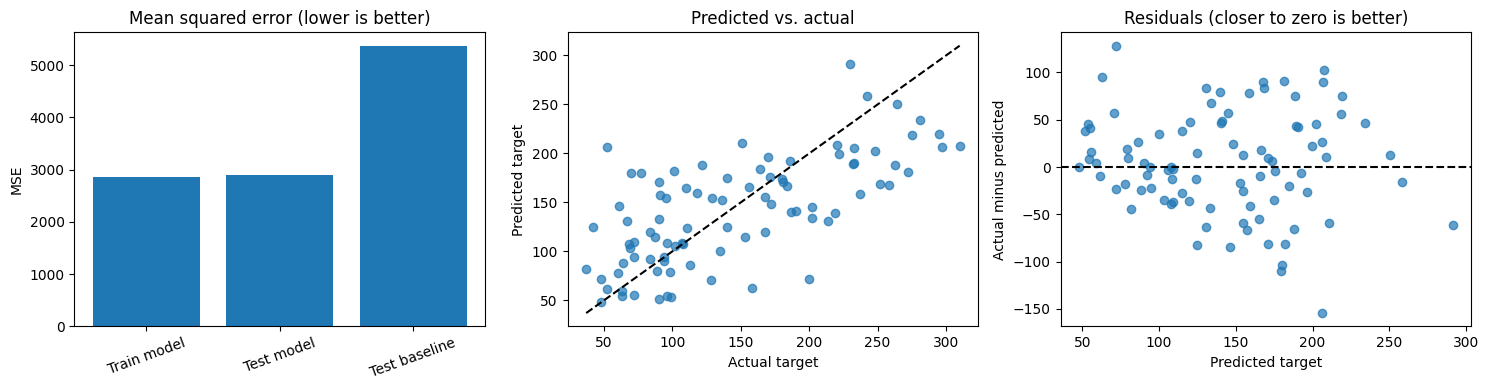

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))  # Create three regression diagnostics.
axes[0].bar(["Train model", "Test model", "Test baseline"], [d_train_mse, d_test_mse, d_baseline_mse])  # Compare squared errors.
axes[0].set_title("Mean squared error (lower is better)")  # Name the error comparison.
axes[0].tick_params(axis="x", labelrotation=20)  # Rotate the category labels.
axes[0].set_ylabel("MSE")  # Label the error units.
axes[1].scatter(yd_test, yd_pred, alpha=0.7)  # Compare true and predicted targets.
axes[1].plot([yd_test.min(), yd_test.max()], [yd_test.min(), yd_test.max()], "k--")  # Show perfect predictions.
axes[1].set_xlabel("Actual target")  # Label observed values.
axes[1].set_ylabel("Predicted target")  # Label model estimates.
axes[1].set_title("Predicted vs. actual")  # Name the scatter plot.
axes[2].scatter(yd_pred, yd_test - yd_pred, alpha=0.7)  # Plot errors against predictions.
axes[2].axhline(0, color="black", linestyle="--")  # Mark zero prediction error.
axes[2].set_xlabel("Predicted target")  # Label the horizontal axis.
axes[2].set_ylabel("Actual minus predicted")  # Label the residual size.
axes[2].set_title("Residuals (closer to zero is better)")  # Identify the error pattern.
plt.tight_layout()  # Prevent overlapping annotations.
plt.show()  # Display the regression plots.

### Reading the diabetes results

- **MSE:** large misses receive an extra penalty because errors are squared. Compare the model's **test MSE** with the mean-prediction baseline to see whether the model learned anything useful.
- **Predicted vs. actual:** points on the dashed 45° line are exact predictions; distance from it shows the error.
- **Residuals:** errors around zero are good, but systematic patterns suggest limits of a straight-line model.
- **Generalization:** if the training MSE is much smaller than testing MSE, the model may not transfer as well to unseen examples. This is evidence to investigate, not proof of overfitting.

## 3. Logistic regression — Iris dataset (three classes)

**Question:** From four flower measurements, which of the three Iris species does the flower belong to?

Because this is classification, use **accuracy** (fraction correctly labeled) and a **confusion matrix** (the kinds of labeling mistakes). `stratify=y` preserves class proportions across the training and test sets.

In [4]:
iris = load_iris()  # Load the three-species flower dataset.
X_i = iris.data  # Extract flower measurement features.
y_i = iris.target  # Extract species labels 0, 1, and 2.
Xi_train, Xi_test, yi_train, yi_test = train_test_split(X_i, y_i, test_size=0.2, random_state=RANDOM_STATE, stratify=y_i)  # Make a balanced 80/20 split.
iris_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))  # Define a multiclass classification pipeline.
iris_model.fit(Xi_train, yi_train)  # Learn feature scaling and class boundaries.
yi_train_pred = iris_model.predict(Xi_train)  # Predict training labels.
yi_pred = iris_model.predict(Xi_test)  # Predict test labels.
i_train_accuracy = accuracy_score(yi_train, yi_train_pred)  # Measure training accuracy.
i_test_accuracy = accuracy_score(yi_test, yi_pred)  # Measure held-out test accuracy.
i_dummy = DummyClassifier(strategy="most_frequent")  # Define a majority-class baseline.
i_dummy.fit(Xi_train, yi_train)  # Find the most common training class.
i_baseline_accuracy = accuracy_score(yi_test, i_dummy.predict(Xi_test))  # Score the test baseline.
print(f"Iris: {len(yi_train)} train / {len(yi_test)} test samples")  # Show split sizes.
print(f"Train accuracy: {i_train_accuracy:.3f}; test accuracy: {i_test_accuracy:.3f}")  # Print model scores.
print(f"Majority-class baseline accuracy: {i_baseline_accuracy:.3f}")  # Print the reference score.

Iris: 120 train / 30 test samples
Train accuracy: 0.958; test accuracy: 0.933
Majority-class baseline accuracy: 0.333


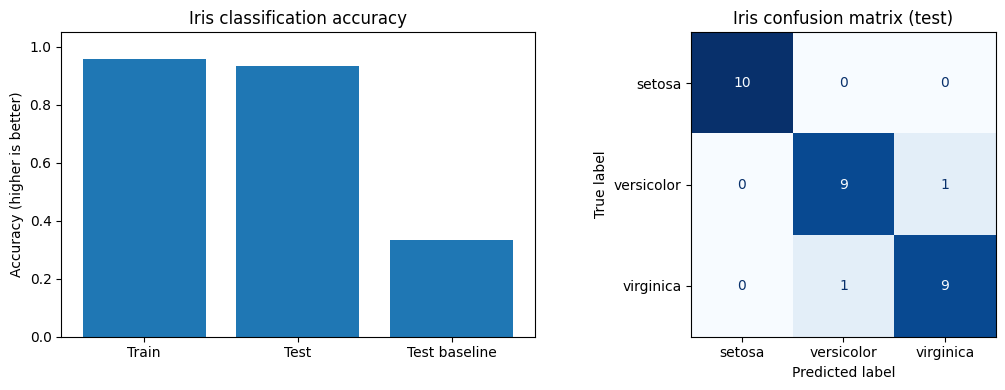

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))  # Create an accuracy chart and confusion matrix.
axes[0].bar(["Train", "Test", "Test baseline"], [i_train_accuracy, i_test_accuracy, i_baseline_accuracy])  # Compare three accuracy scores.
axes[0].set_ylim(0, 1.05)  # Set the possible accuracy range.
axes[0].set_ylabel("Accuracy (higher is better)")  # Describe the vertical metric.
axes[0].set_title("Iris classification accuracy")  # Label the accuracy panel.
ConfusionMatrixDisplay.from_predictions(yi_test, yi_pred, display_labels=iris.target_names, ax=axes[1], colorbar=False, cmap="Blues")  # Display class-by-class errors.
axes[1].set_title("Iris confusion matrix (test)")  # Identify the held-out set.
plt.tight_layout()  # Make both panels readable.
plt.show()  # Display the classification plots.

### Reading the Iris results

- An accuracy of **0.90** means 90% of the **test** flowers were labeled correctly; your exact score is printed above.
- In the confusion matrix, **rows are actual species** and **columns are predicted species**. Values on the **diagonal** are correct predictions; values off the diagonal are errors.
- A baseline that always chooses the most common species offers a minimum useful point of comparison. Accuracy alone would hide *which* species were confused.

## 4. Logistic regression — Breast Cancer Wisconsin (two classes)

This dataset provides **binary classification** and lets us examine **probabilities** instead of class labels alone. In scikit-learn's version, label `0` means **malignant** and label `1` means **benign**. The model's positive class for the ROC display is therefore **benign**.

Alongside accuracy, we plot **log loss**, which checks whether the model assigns high probability to the true class. **Lower log loss is better**. An ROC curve shows performance as the decision threshold varies, while the reported ROC AUC summarizes ranking performance.

> This is a teaching example only; the model is **not** a clinical diagnostic tool.

In [6]:
cancer = load_breast_cancer()  # Load the binary classification dataset.
X_c = cancer.data  # Select the thirty numeric features.
y_c = cancer.target  # Select malignant-or-benign labels.
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_c, y_c, test_size=0.2, random_state=RANDOM_STATE, stratify=y_c)  # Preserve class proportions.
cancer_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))  # Set up scaled logistic regression.
cancer_model.fit(Xc_train, yc_train)  # Train on the training subset only.
yc_pred_train = cancer_model.predict(Xc_train)  # Predict classes on training data.
yc_pred = cancer_model.predict(Xc_test)  # Predict classes on test data.
yc_prob_train = cancer_model.predict_proba(Xc_train)  # Estimate training class probabilities.
yc_prob_test = cancer_model.predict_proba(Xc_test)  # Estimate test class probabilities.
c_train_accuracy = accuracy_score(yc_train, yc_pred_train)  # Calculate training accuracy.
c_test_accuracy = accuracy_score(yc_test, yc_pred)  # Calculate testing accuracy.
c_train_logloss = log_loss(yc_train, yc_prob_train)  # Calculate training log loss.
c_test_logloss = log_loss(yc_test, yc_prob_test)  # Calculate testing log loss.
print(f"Breast Cancer: {len(yc_train)} train / {len(yc_test)} test samples")  # Display sample counts.
print(f"Accuracy: train = {c_train_accuracy:.3f}, test = {c_test_accuracy:.3f}")  # Compare class correctness.
print(f"Log loss: train = {c_train_logloss:.3f}, test = {c_test_logloss:.3f}")  # Compare probability errors.
print(f"Example class probabilities [malignant, benign]: {yc_prob_test[0].round(3)}")  # Show an example probability pair.

Breast Cancer: 455 train / 114 test samples
Accuracy: train = 0.989, test = 0.982
Log loss: train = 0.051, test = 0.078
Example class probabilities [malignant, benign]: [1. 0.]


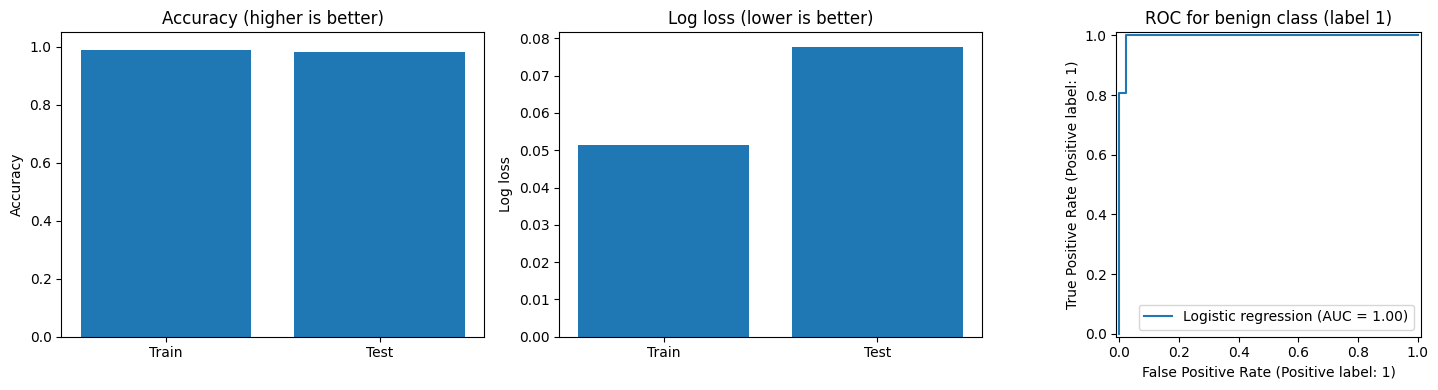

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))  # Create three complementary diagnostics.
axes[0].bar(["Train", "Test"], [c_train_accuracy, c_test_accuracy])  # Compare classification accuracy.
axes[0].set_ylim(0, 1.05)  # Keep the full accuracy range visible.
axes[0].set_title("Accuracy (higher is better)")  # Label the score comparison.
axes[0].set_ylabel("Accuracy")  # Name the first vertical axis.
axes[1].bar(["Train", "Test"], [c_train_logloss, c_test_logloss])  # Compare probability log loss.
axes[1].set_title("Log loss (lower is better)")  # Label the loss comparison.
axes[1].set_ylabel("Log loss")  # Name the loss units.
RocCurveDisplay.from_estimator(cancer_model, Xc_test, yc_test, ax=axes[2], name="Logistic regression")  # Plot the test ROC curve.
axes[2].set_title("ROC for benign class (label 1)")  # Clarify the positive class.
plt.tight_layout()  # Adjust all three charts.
plt.show()  # Display the plots.

### Reading the breast cancer results

- **Accuracy** uses predicted class labels, usually obtained by choosing the class with the highest predicted probability.
- **Log loss** also assesses the *confidence* of predictions: confident mistakes are penalized heavily. Good accuracy does not guarantee good probabilities.
- **ROC:** curves near the top-left indicate better separation between the two labels; the diagonal represents random ranking. **AUC = 1** means perfect ranking, and **AUC ≈ 0.5** means near-random ranking.
- **Training versus testing:** the test values are the most important estimates here, since the test examples were not used to fit the model.

## 5. Logistic regression — Wine dataset (three classes)

One more multiclass example with **13 measured chemical features** and **three cultivars**. The same six-stage workflow works without changing the algorithm. Watch the confusion matrix: a high overall accuracy can still conceal mistakes in one particular class.

In [8]:
wine = load_wine()  # Load the multiclass wine dataset.
X_w = wine.data  # Extract thirteen chemical measurements.
y_w = wine.target  # Extract the three cultivar labels.
Xw_train, Xw_test, yw_train, yw_test = train_test_split(X_w, y_w, test_size=0.2, random_state=RANDOM_STATE, stratify=y_w)  # Split data while balancing classes.
wine_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))  # Build the same logistic pipeline.
wine_model.fit(Xw_train, yw_train)  # Fit the pipeline on training examples.
yw_pred_train = wine_model.predict(Xw_train)  # Predict training labels.
yw_pred = wine_model.predict(Xw_test)  # Predict unseen test labels.
w_train_accuracy = accuracy_score(yw_train, yw_pred_train)  # Measure training classification accuracy.
w_test_accuracy = accuracy_score(yw_test, yw_pred)  # Measure test classification accuracy.
w_dummy = DummyClassifier(strategy="most_frequent")  # Create a majority-class reference model.
w_dummy.fit(Xw_train, yw_train)  # Learn the majority class from training data.
w_baseline_accuracy = accuracy_score(yw_test, w_dummy.predict(Xw_test))  # Calculate baseline test accuracy.
print(f"Wine: {len(yw_train)} train / {len(yw_test)} test samples")  # Show the sample split.
print(f"Accuracy: train = {w_train_accuracy:.3f}, test = {w_test_accuracy:.3f}")  # Display model results.
print(f"Majority-class test accuracy: {w_baseline_accuracy:.3f}")  # Compare a simple baseline.

Wine: 142 train / 36 test samples
Accuracy: train = 1.000, test = 0.972
Majority-class test accuracy: 0.389


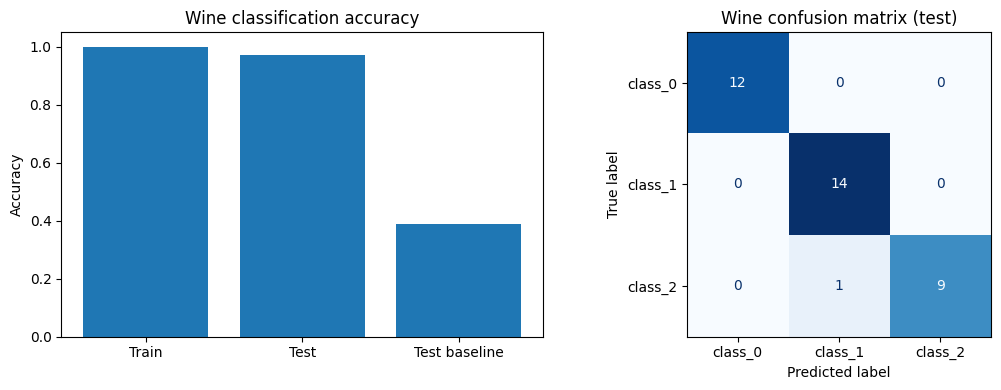

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))  # Show two wine-classification views.
axes[0].bar(["Train", "Test", "Test baseline"], [w_train_accuracy, w_test_accuracy, w_baseline_accuracy])  # Plot class accuracy scores.
axes[0].set_ylim(0, 1.05)  # Show scores on a zero-to-one scale.
axes[0].set_ylabel("Accuracy")  # Label the plotted metric.
axes[0].set_title("Wine classification accuracy")  # Label the first panel.
ConfusionMatrixDisplay.from_predictions(yw_test, yw_pred, display_labels=wine.target_names, ax=axes[1], colorbar=False, cmap="Blues")  # Plot correctly and incorrectly classified labels.
axes[1].set_title("Wine confusion matrix (test)")  # Identify the classification errors.
plt.tight_layout()  # Prevent the labels overlapping.
plt.show()  # Display both charts.

### Reading the Wine results

Compare the **test accuracy** with the majority-class baseline. Then inspect the **off-diagonal** cells: these show which cultivars the model mistakes for one another. Different datasets can have very different difficulties, so their accuracy values are **not a fair algorithm leaderboard**.

## 6. Optional: a learning curve without writing a training loop

A **learning curve** plots model performance against the **number of training examples** rather than training epochs. scikit-learn fits several copies of the model for us; **we still never write an optimization loop**.

For Iris, train and cross-validation accuracy approaching each other with more examples suggests better generalization. A persistent large gap may indicate overfitting. The training-size points and cross-validation results come entirely from the original Iris **training split**; the held-out test set is untouched.

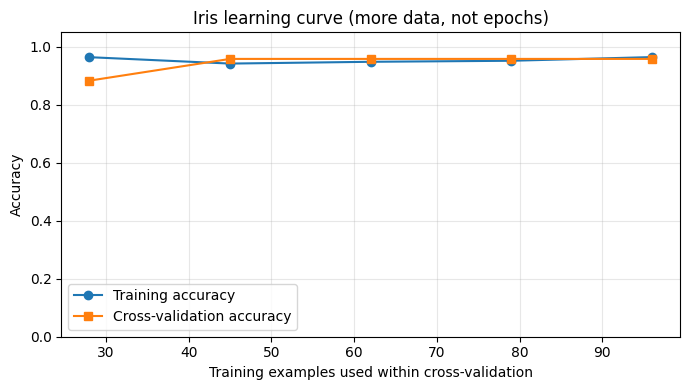

In [10]:
size_i, score_train_i, score_cv_i = learning_curve(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), Xi_train, yi_train, train_sizes=np.linspace(0.3, 1.0, 5), cv=5, scoring="accuracy")  # Fit models on increasing training subsets.
plt.figure(figsize=(7, 4))  # Create an accuracy learning-curve figure.
plt.plot(size_i, score_train_i.mean(axis=1), "o-", label="Training accuracy")  # Show mean training accuracy.
plt.plot(size_i, score_cv_i.mean(axis=1), "s-", label="Cross-validation accuracy")  # Show mean validation accuracy.
plt.ylim(0, 1.05)  # Use the full accuracy range.
plt.xlabel("Training examples used within cross-validation")  # Explain the horizontal axis.
plt.ylabel("Accuracy")  # Label the measured score.
plt.title("Iris learning curve (more data, not epochs)")  # Clarify what changes here.
plt.legend()  # Identify both accuracy lines.
plt.grid(alpha=0.3)  # Add a light reading guide.
plt.tight_layout()  # Keep all labels visible.
plt.show()  # Display the learning curve.

## 7. Summary: one pipeline, two objectives

| Step | Numeric target: linear regression | Class target: logistic regression |
|:--|:--|:--|
| Load | `load_diabetes()` | `load_iris()`, `load_breast_cancer()`, `load_wine()` |
| Split | `train_test_split(X, y)` | `train_test_split(X, y, stratify=y)` |
| Build | `make_pipeline(StandardScaler(), LinearRegression())` | `make_pipeline(StandardScaler(), LogisticRegression())` |
| Train | `model.fit(X_train, y_train)` | `model.fit(X_train, y_train)` |
| Predict | `model.predict(X_test)` → numbers | `model.predict(X_test)` → class labels |
| Evaluate | MSE, MAE, R²; residual plot | Accuracy, confusion matrix; log loss / ROC for binary labels |

**Important concepts to retain**

1. **Never learn scaling parameters on the whole dataset before splitting.** The pipeline handles this correctly.
2. **Training score** describes how the model fits seen data; **test score** estimates performance on unseen data.
3. A **baseline** asks whether the model improves on a simple guess.
4. No dataset here is a realistic deployment benchmark; they are small teaching datasets.

### Try-it-yourself questions

- Change `test_size=0.2` to `test_size=0.3`. How do the test metrics change?
- Remove `StandardScaler()` from logistic regression. How do the results change, and why?
- Find one wrong prediction in a confusion matrix. Which true class was mistaken for which predicted class?
- For diabetes, compare the baseline MSE against the model MSE. What does this say about usefulness?
- For the breast cancer example, why might **log loss** change even when **accuracy** stays constant?

### Official references

- [Getting started with scikit-learn](https://scikit-learn.org/stable/getting_started)
- [scikit-learn toy datasets](https://scikit-learn.org/stable/datasets/toy_dataset.html)
- [Pipelines and composite estimators](https://scikit-learn.org/stable/modules/compose.html)